# Notebook 10 — Trading decision layer
## Goal and scope
Translate NB9 distributions into an auditable hypothetical long-or-cash strategy, with delayed execution, costs, bounded position sizes and an explicit cash/share ledger. Compare the same decision rule applied to analog and recent-history forecasts, plus buy-and-hold and cash.

**This is an exploratory historical experiment.** NB9's later period has already been inspected. The rule below is a transparent research default, not a calibrated optimum or a claim of profitability. No strategy parameters are selected from the results. Three sessions is the primary horizon; the other four horizons and all cost scenarios are sensitivity checks. A new locked prospective period remains necessary.

The notebook consumes a verified NB9 snapshot offline. It does not execute earlier notebooks or place orders. Adjusted closes are a total-return-like proxy, not historical executable quotes; costs are assumed scenarios, not measured fills. NB9 found better distribution CRPS but worse point and directional scores than the recent baseline—do not equate that distribution improvement with a trading edge.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
INPUT_DIR = None  # Directory containing NB9 forecasts.csv and run_manifest.json
MARKET_PATH = None  # Optional matching NB3 market CSV when using external NB9 outputs
ROOT=Path.cwd(); OUT=ROOT/'outputs'/'notebook_10';OUT.mkdir(parents=True,exist_ok=True)
PRIMARY_H=3; CAPITAL=100_000.; COST_BPS=5.; EDGE_BUFFER_BPS=5.
VOL_TARGET=.10; TAIL_BUDGET=.01; MAX_WEIGHT=1.; VOL_WINDOW=20
COST_GRID=[0.,2.,5.,10.,20.]; SEED=1731; BOOT_REPS=499; BLOCK=20
assert PRIMARY_H in range(1,6) and 0<MAX_WEIGHT<=1 and CAPITAL>0
assert COST_BPS>=0 and EDGE_BUFFER_BPS>=0
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':120,'font.size':11,
 'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
pd.set_option('display.max_rows',15)
def digest(p):return hashlib.sha256(p.read_bytes()).hexdigest()
def valid_folder(p):
    if not (p/'forecasts.csv').is_file() or not (p/'run_manifest.json').is_file():return False
    return str(json.loads((p/'run_manifest.json').read_text()).get('notebook','')).startswith('9 ')
if INPUT_DIR is None:
    # Prefer live NB9 output over bundled fallback, but never guess between different exports.
    live=[ROOT/'outputs/notebook_9',ROOT/'notebook_9/outputs/notebook_9',ROOT.parent/'notebook_9/outputs/notebook_9']
    candidates=list(dict.fromkeys(p.resolve() for p in live if valid_folder(p)))
    if not candidates:candidates=[p.resolve() for p in [ROOT/'inputs',ROOT/'notebook_10/inputs'] if valid_folder(p)]
    if not candidates:raise FileNotFoundError(f'No NB9 export found from {ROOT}. Set INPUT_DIR or retain bundled inputs/.')
    if len({tuple(digest(p/name) for name in ['forecasts.csv','forecast_configuration.json','run_manifest.json']) for p in candidates})>1:raise ValueError('Different NB9 exports found; set INPUT_DIR explicitly.')
    INPUT_DIR=candidates[0]
else:
    INPUT_DIR=Path(INPUT_DIR).expanduser().resolve()
    if not valid_folder(INPUT_DIR):raise ValueError('INPUT_DIR must contain an NB9 forecast export.')
source=json.loads((INPUT_DIR/'run_manifest.json').read_text())
config=json.loads((INPUT_DIR/'forecast_configuration.json').read_text())
if (INPUT_DIR/'checksums.json').exists():
    for name,expected in json.loads((INPUT_DIR/'checksums.json').read_text()).items():
        if digest(INPUT_DIR/name)!=expected:raise ValueError('Checksum mismatch: '+name)
market_name='SYNTHETIC_DEMO_ohlcv.csv' if source['source']['synthetic'] else 'market_ohlcv_snapshot.csv'
expected=source['input_hashes'][market_name]
if MARKET_PATH is None:
    options=[INPUT_DIR/market_name,INPUT_DIR.parent.parent/'inputs'/market_name,ROOT/'assets'/market_name,
      ROOT/'inputs'/market_name,ROOT.parent/'notebook_9/inputs'/market_name,ROOT/'notebook_9/inputs'/market_name]
    matches=[p.resolve() for p in options if p.is_file() and digest(p)==expected]
    if not matches:raise FileNotFoundError('No market snapshot matches NB9 provenance. Set MARKET_PATH to its NB3 market CSV.')
    MARKET_PATH=matches[0]
else:MARKET_PATH=Path(MARKET_PATH).expanduser().resolve()
assert digest(MARKET_PATH)==expected,'Market snapshot does not match NB9'
assert config['entry_delay_sessions']==1 and config['horizons']==[1,2,3,4,5]
market=pd.read_csv(MARKET_PATH,index_col=0,parse_dates=True,float_precision='round_trip')
assert market.index.is_unique and market.index.is_monotonic_increasing
price=market.Close.astype(float);assert price.gt(0).all() and np.isfinite(price).all()
forecasts=pd.read_csv(INPUT_DIR/'forecasts.csv',parse_dates=['date','label_end'])
assert not forecasts.duplicated(['date','model','horizon']).any()
assert forecasts.supported.isin([True,False]).all()
assert forecasts.date.min()>pd.Timestamp(source['calibration_end'])
vol=np.log(price).diff().rolling(VOL_WINDOW,min_periods=VOL_WINDOW).std()*np.sqrt(252)
LABEL=('SYNTHETIC DEMO' if source['source']['synthetic'] else source['source']['ticker'])+' · NB10'
def finish(fig,name):
    fig.suptitle(LABEL,fontsize=11,color='#555555');fig.savefig(OUT/name,dpi=150,bbox_inches='tight');plt.show()
def date_axis(ax):
    loc=mdates.AutoDateLocator(minticks=3,maxticks=5);ax.xaxis.set_major_locator(loc);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
print('NB9 inputs:',INPUT_DIR,'; matching market:',MARKET_PATH)
print('Snapshot through',price.index[-1].date(),'; no current-market claim.')

NB9 inputs: /Users/trush/Documents/Trading/Codex/outputs/notebook_9 ; matching market: /Users/trush/Documents/Trading/Codex/assets/market_ohlcv_snapshot.csv
Snapshot through 2026-10-01 ; no current-market claim.


## 1. Decision rule and information clock
At close $t$, use only the NB9 mean log return $\mu_{t,h}$, 10th-percentile outcome $q_{.1,t,h}$, support flag and trailing volatility. The entry is at close $t+1$, exit at close $t+1+h$. Origin positions are spaced exactly $h$ sessions apart, so positions never overlap; exit and next entry may occur at the same close. Cash remains idle after a skipped entry. Signals arriving while a position is open are not acted upon until their scheduled entry.

For proportional one-way cost $c$, the exact full-allocation break-even log price move is
$$b(c)=\log\frac{1+c}{1-c}.$$
The long condition is supported and $\mu_{t,h}>b(c)+\delta$, where $\delta=5$ log basis points is a fixed research buffer. Mean log return is a geometric-growth proxy, **not** expected simple return: $E[e^Y-1]\ne e^{E[Y]}-1$. We avoid reconstructing missing distribution moments or claiming a Kelly optimum from NB9's summary exports.

The fraction of account equity allocated, including entry cost, is
$$w_t=I_t\min\left(1,\frac{0.10}{\widehat\sigma_{t,ann}},\frac{0.01}{\max(0,-\operatorname{expm1}(q_{.1,t,h}),10^{-6})}\right).$$
This is a sizing heuristic: the empirical tail quantile is not a worst-case loss, and neither budget guarantees a volatility or loss limit. Weight is set at entry and drifts until exit. There is no leverage, shorting, intraday stop or claim of guaranteed execution. The support gate is identical for analog and recent forecasts, isolating their decision summaries under a shared geometry eligibility screen.

,date,mean,q10,vol_ann,weight,reason
0,2024-02-14,0.004159,-0.009805,0.123025,0.812841,long
1,2024-02-20,0.003364,-0.011225,0.121729,0.821496,long
2,2024-02-23,-0.000842,-0.020269,0.138997,0.000000,insufficient edge
3,2024-02-28,0.000951,-0.016035,0.138324,0.000000,insufficient edge
4,2024-03-04,0.001935,-0.011217,0.113919,0.877819,long
5,2024-03-07,0.001207,-0.018498,0.121931,0.000000,insufficient edge
6,2024-03-12,0.000523,-0.014087,0.128503,0.000000,insufficient edge
7,2024-03-15,0.003877,-0.011225,0.115649,0.864683,long


/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_3663/797829760.py:61: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.suptitle(LABEL,fontsize=11,color='#555555');fig.savefig(OUT/name,dpi=150,bbox_inches='tight');plt.show()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


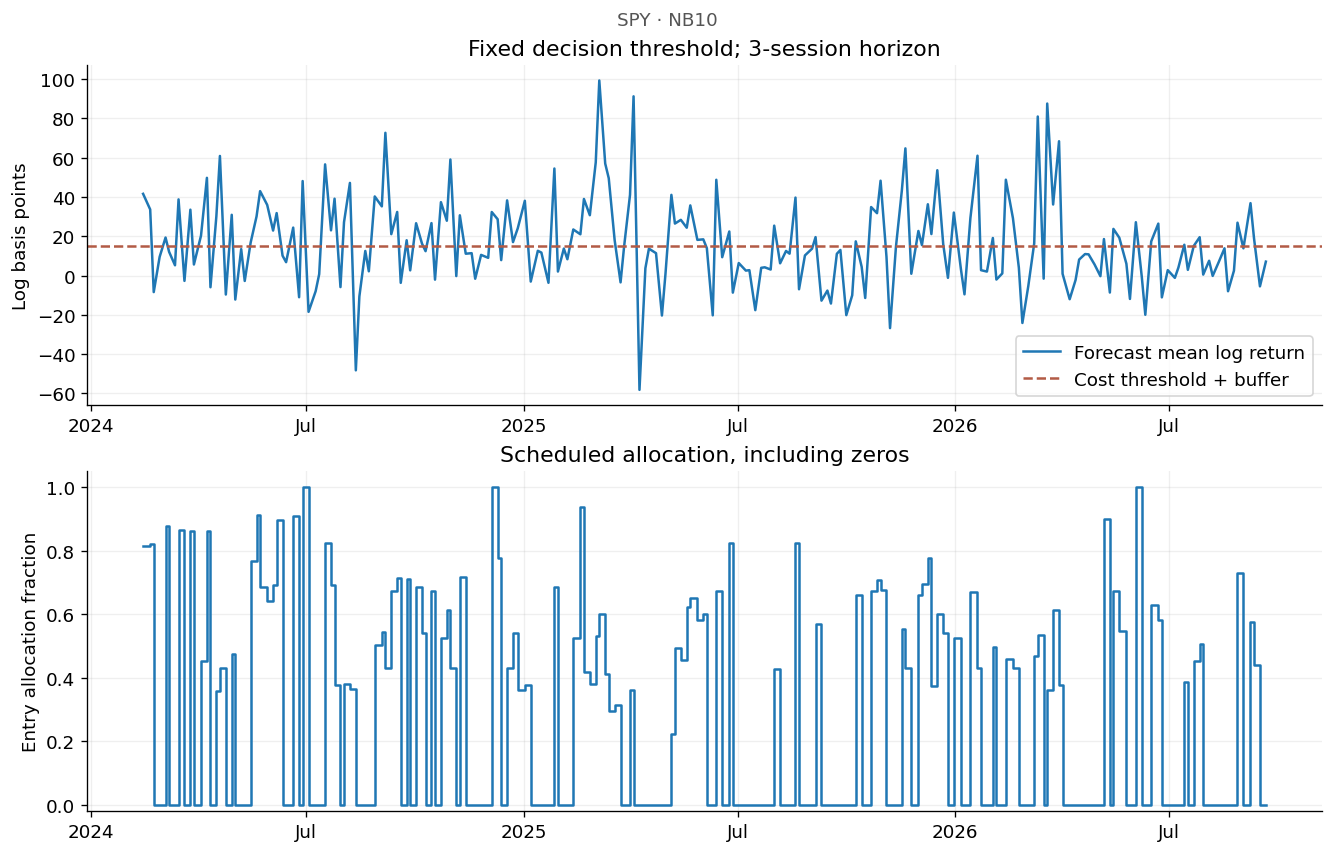

In [4]:
def decisions(h,model='analog',offset=0):
    f=forecasts[(forecasts.horizon==h)&(forecasts.model==model)].sort_values('date').copy()
    pos=price.index.get_indexer(f.date);assert (pos>=0).all() and np.all(np.diff(pos)==1)
    # Scheduled origins are fixed from the first available forecast; no selection by returns.
    f=f.iloc[offset::h].copy();pos=price.index.get_indexer(f.date)
    assert (pos+1+h<len(price)).all()
    f['signal_pos']=pos;f['entry_pos']=pos+1;f['exit_pos']=pos+1+h
    assert np.array_equal(price.index[f.exit_pos],pd.DatetimeIndex(f.label_end))
    reconstructed=np.log(price.iloc[f.exit_pos].to_numpy()/price.iloc[f.entry_pos].to_numpy())
    assert np.allclose(reconstructed,f.actual,atol=1e-12)
    f['vol_ann']=vol.reindex(f.date).to_numpy();assert f.vol_ann.gt(0).all()
    f['threshold']=np.log((1+COST_BPS/1e4)/(1-COST_BPS/1e4))+EDGE_BUFFER_BPS/1e4
    f['eligible']=f.supported.astype(bool)&(f['mean']>f.threshold)
    f['tail_loss']=np.maximum(-np.expm1(f.q10),1e-6)
    f['weight']=np.minimum.reduce([np.full(len(f),MAX_WEIGHT),VOL_TARGET/f.vol_ann,TAIL_BUDGET/f.tail_loss])*f.eligible
    f['reason']=np.where(~f.supported,'unsupported',np.where(~f.eligible,'insufficient edge','long'))
    assert f.weight.between(0,1).all() and (f.entry_pos>f.signal_pos).all()
    return f.reset_index(drop=True)
plans={m:decisions(PRIMARY_H,m) for m in ['analog','recent']}
assert np.array_equal(plans['analog'].supported,plans['recent'].supported),'Baseline support gates differ'
plan=plans['analog'];display(plan[['date','mean','q10','vol_ann','weight','reason']].head(8))
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained')
axes[0].plot(plan.date,plan['mean']*1e4,label='Forecast mean log return');axes[0].axhline(plan.threshold.iloc[0]*1e4,color='#b25b45',ls='--',label='Cost threshold + buffer')
axes[0].set(ylabel='Log basis points',title='Fixed decision threshold; 3-session horizon');axes[0].legend()
axes[1].step(plan.date,plan.weight,where='post');axes[1].set(ylabel='Entry allocation fraction',title='Scheduled allocation, including zeros',ylim=(-.02,1.05))
for ax in axes:date_axis(ax)
finish(fig,'01_decisions.png')

## 2. Self-financing ledger and cost accounting
At entry, equity $E$ and allocation $w$ buy $Q=wE/[P_{entry}(1+c)]$ adjusted-price units, leaving cash $E-wE$. At exit, cash receives $QP_{exit}(1-c)$. Therefore the exact isolated-trade account factor is
$$\frac{E_{exit}}{E_{entry^-}}=1-w+w\frac{P_{exit}}{P_{entry}}\frac{1-c}{1+c}.$$
The ledger marks positions every close and charges each purchase and sale separately, including same-close exit/re-entry. No netting benefit is assumed. Cash earns zero; taxes, fixed fees, market impact, borrowing and capacity constraints are omitted. Five basis points per side is a scenario combining spread, slippage and proportional fees, not an estimate for SPY. Fractional adjusted units are a research accounting convention; raw shares and explicit corporate-action cash flows are required for execution-grade simulation.

A decision made at $t$ fixes the **fraction**, not the future dollar order. The next-close simulator allocates using equity at that close. Thus actual implementation would require an equity-aware fractional/notional execution mechanism; exact fill-at-close sizing is an idealization. All strategies share the same evaluation calendar, including the initial cash day and final liquidation.

,total_return,cagr,annual_vol,sharpe_zero_cash,max_drawdown,mean_exposure,trades,win_fraction,fees,turnover_on_initial
strategy,,,,,,,,,,
analog,0.0449,0.0171,0.0585,0.3184,-0.0974,0.2735,100.0,0.6100,6297.1853,125.9437
recent,0.0099,0.0038,0.0790,0.0873,-0.1501,0.5457,194.0,0.5567,12059.2538,241.1851
buy_hold,0.5852,0.1939,0.1574,1.2045,-0.1876,0.9985,1.0,1.0000,129.2756,2.5855
cash,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0,NaN,0.0000,0.0000


/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_3663/797829760.py:61: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.suptitle(LABEL,fontsize=11,color='#555555');fig.savefig(OUT/name,dpi=150,bbox_inches='tight');plt.show()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


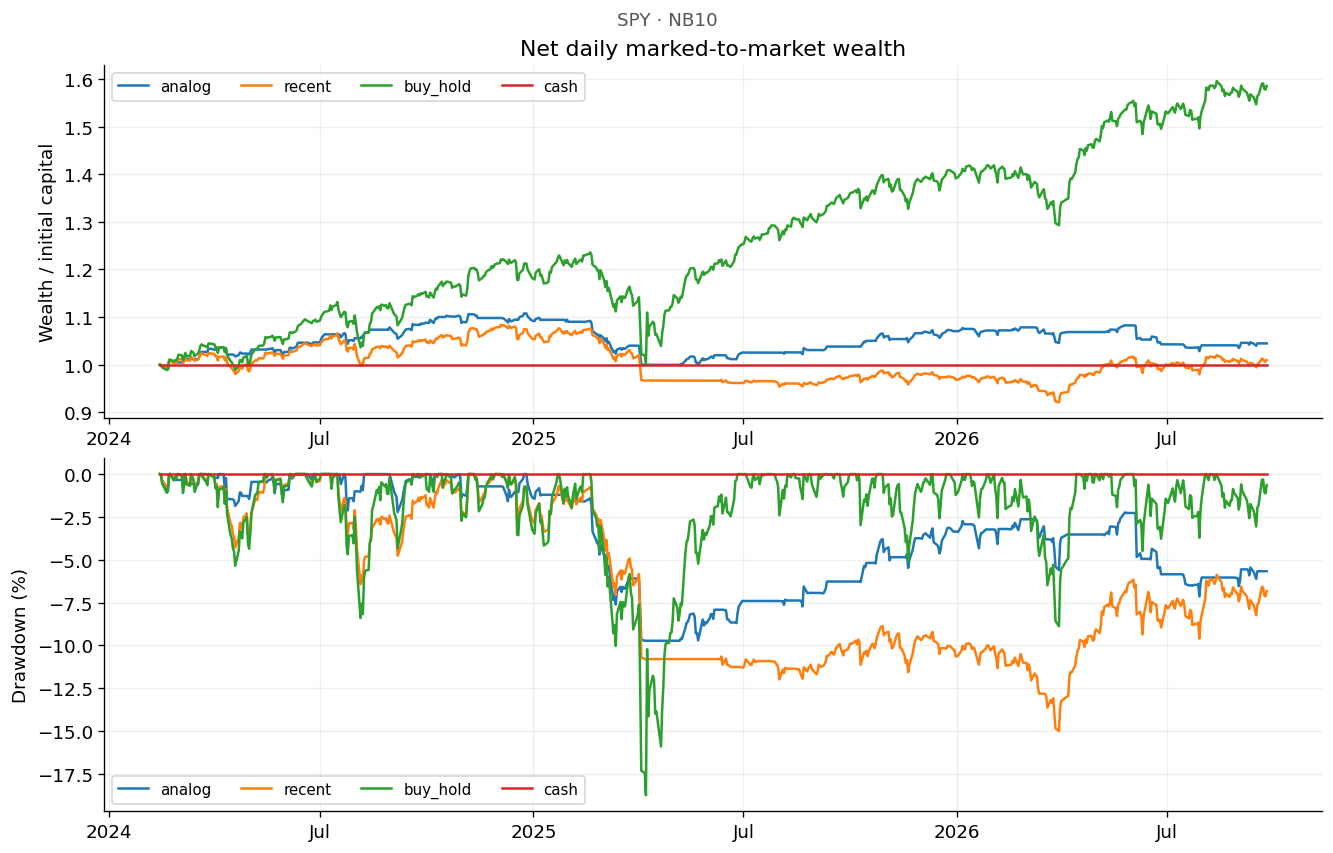

In [6]:
def simulate(p,cost_bps=COST_BPS,window=None):
    c=cost_bps/1e4;assert 0<=c<1
    start=int(p.signal_pos.min()) if window is None else window[0]
    end=int(p.exit_pos.max()) if window is None else window[1]
    events={int(r.entry_pos):r for r in p.itertuples() if r.weight>0}
    cash=CAPITAL;units=0.;active=None;rows=[];trades=[]
    for k in range(start,end+1):
        px=float(price.iloc[k]);fees=0.;traded=0.
        if active is not None and k==active['exit_pos']:
            proceeds=units*px;fee=proceeds*c;cash+=proceeds-fee;fees+=fee;traded+=proceeds
            active.update(exit_date=price.index[k],exit_price=px,exit_fee=fee,
                pnl=proceeds-fee-active['budget'],net_return=(proceeds-fee)/active['budget']-1)
            trades.append(active);units=0.;active=None
        if k in events:
            assert active is None,'Overlapping positions'
            r=events[k];equity=cash;budget=equity*r.weight;notional=budget/(1+c)
            units=notional/px;fee=notional*c;cash-=budget;fees+=fee;traded+=notional
            active=dict(signal_date=r.date,entry_date=price.index[k],exit_pos=int(r.exit_pos),
                entry_price=px,weight=r.weight,budget=budget,units=units,entry_fee=fee)
        eq=cash+units*px
        assert cash>=-1e-7 and eq>0
        rows.append(dict(date=price.index[k],equity=eq,cash=cash,units=units,
            exposure=units*px/eq,fee=fees,traded_notional=traded))
    assert active is None and units==0,'Unliquidated final position'
    ledger=pd.DataFrame(rows).set_index('date');ledger['return']=ledger.equity.pct_change().fillna(0)
    ledger['drawdown']=ledger.equity/ledger.equity.cummax()-1
    tr=pd.DataFrame(trades,columns=['signal_date','entry_date','exit_pos','entry_price','weight','budget','units','entry_fee','exit_date','exit_price','exit_fee','pnl','net_return'])
    assert np.isclose(ledger.equity.iloc[-1]-CAPITAL,tr.pnl.sum() if len(tr) else 0,atol=1e-7)
    return ledger,tr
window=(int(plan.signal_pos.min()),int(plan.exit_pos.max()))
results={m:simulate(p,window=window) for m,p in plans.items()}
buyhold=plan.iloc[[0]].copy();buyhold['weight']=1.;buyhold['exit_pos']=window[1]
results['buy_hold']=simulate(buyhold,window=window)
cashplan=plan.copy();cashplan['weight']=0.;results['cash']=simulate(cashplan,window=window)
def metrics(ledger,trades):
    ret=ledger['return'].iloc[1:];n=len(ret);sd=ret.std(ddof=1)
    return dict(total_return=ledger.equity.iloc[-1]/CAPITAL-1,cagr=(ledger.equity.iloc[-1]/CAPITAL)**(252/n)-1,
        annual_vol=sd*np.sqrt(252),sharpe_zero_cash=np.sqrt(252)*ret.mean()/sd if sd>0 else np.nan,
        max_drawdown=ledger.drawdown.min(),mean_exposure=ledger.exposure.iloc[:-1].mean(),
        trades=len(trades),win_fraction=(trades.pnl>0).mean() if len(trades) else np.nan,
        fees=ledger.fee.sum(),turnover_on_initial=ledger.traded_notional.sum()/CAPITAL)
summary=pd.DataFrame({m:metrics(*r) for m,r in results.items()}).T
summary.index.name='strategy';display(summary.round(4))
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained')
for m,(l,tr) in results.items():
    axes[0].plot(l.index,l.equity/CAPITAL,label=m);axes[1].plot(l.index,l.drawdown*100,label=m)
axes[0].set(ylabel='Wealth / initial capital',title='Net daily marked-to-market wealth');axes[1].set(ylabel='Drawdown (%)')
for ax in axes:date_axis(ax);ax.legend(ncol=4,fontsize=9)
finish(fig,'02_equity_drawdown.png')

## 3. Participation, turnover and realized trade outcomes
CAGR uses 252 observed sessions/year; the displayed Sharpe-like statistic uses zero-return cash and is descriptive, without an iid significance claim. Drawdown includes entry/exit costs and daily price moves. Trade win fractions are conditional on selected trades and do not describe every forecast origin. Compare risk and exposure before interpreting total-return differences. No strategy is selected by this table.

,reason,scheduled_origins
0,insufficient edge,112
1,long,100
2,unsupported,6


/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_3663/797829760.py:61: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.suptitle(LABEL,fontsize=11,color='#555555');fig.savefig(OUT/name,dpi=150,bbox_inches='tight');plt.show()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


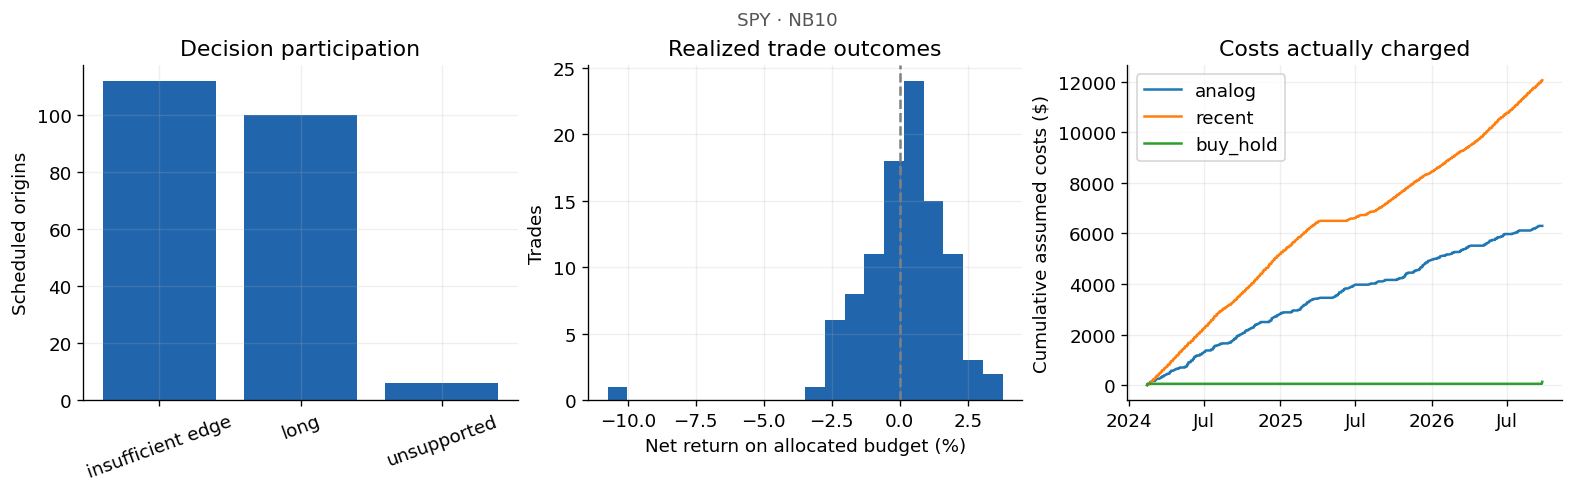

In [8]:
a,tr=results['analog']
counts=plan.reason.value_counts().rename_axis('reason').reset_index(name='scheduled_origins')
display(counts)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
axes[0].bar(counts.reason,counts.scheduled_origins,color='#2166ac');axes[0].tick_params(axis='x',rotation=20);axes[0].set(ylabel='Scheduled origins',title='Decision participation')
if len(tr):axes[1].hist(tr.net_return*100,bins=20,color='#2166ac')
else:axes[1].text(.5,.5,'No trades',ha='center',transform=axes[1].transAxes)
axes[1].axvline(0,color='gray',ls='--');axes[1].set(xlabel='Net return on allocated budget (%)',ylabel='Trades',title='Realized trade outcomes')
for m in ['analog','recent','buy_hold']:
    l,_=results[m];axes[2].plot(l.index,l.fee.cumsum(),label=m)
axes[2].set(ylabel='Cumulative assumed costs ($)',title='Costs actually charged');axes[2].legend();date_axis(axes[2])
finish(fig,'03_participation_costs.png')

## 4. Sensitivity without retrospective selection
Vary one-way costs while **keeping original decisions and allocation fractions fixed**. This isolates execution-cost drag; it does not grant the strategy foresight to change its entry threshold. Changed compounding changes dollar sizes. Separately apply the original rule across all five forecast horizons and each possible schedule offset; holding-period and start-offset effects are diagnostic. Their windows differ slightly, so totals are not a common-window tournament. Do not promote the best horizon, offset or fee assumption to the primary result.

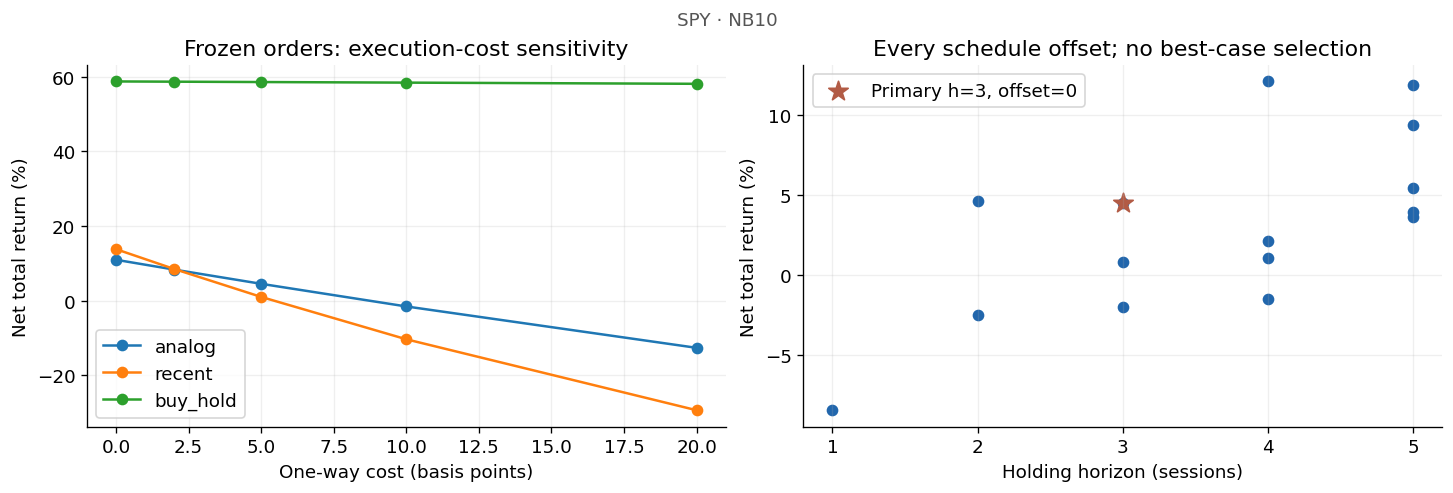

,horizon,offset,total_return,max_drawdown,trades
0,1,0,-0.0843,-0.1302,125
1,2,0,-0.0250,-0.0915,107
2,2,1,0.0464,-0.0634,101
3,3,0,0.0449,-0.0974,100
4,3,1,-0.0195,-0.0987,86
5,3,2,0.0086,-0.0684,97
6,4,0,-0.0149,-0.0808,91
7,4,1,0.0217,-0.0940,93
8,4,2,0.0108,-0.0829,100
9,4,3,0.1212,-0.0533,96


In [10]:
cost_rows=[]
for m in ['analog','recent','buy_hold']:
    p=buyhold if m=='buy_hold' else plans[m]
    for c in COST_GRID:
        l,t=simulate(p,c,window);cost_rows.append(dict(strategy=m,cost_bps=c,**metrics(l,t)))
costs=pd.DataFrame(cost_rows)
sensitivity=[]
for h in range(1,6):
    for offset in range(h):
        p=decisions(h,offset=offset);l,t=simulate(p)
        sensitivity.append(dict(horizon=h,offset=offset,start=str(l.index[0].date()),end=str(l.index[-1].date()),**metrics(l,t)))
sensitivity=pd.DataFrame(sensitivity)
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for m,f in costs.groupby('strategy',sort=False):axes[0].plot(f.cost_bps,f.total_return*100,'o-',label=m)
axes[0].set(xlabel='One-way cost (basis points)',ylabel='Net total return (%)',title='Frozen orders: execution-cost sensitivity');axes[0].legend()
for h,f in sensitivity.groupby('horizon'):axes[1].scatter(np.full(len(f),h),f.total_return*100,color='#2166ac')
axes[1].scatter([PRIMARY_H],[summary.loc['analog','total_return']*100],marker='*',s=150,color='#b25b45',label='Primary h=3, offset=0')
axes[1].set(xticks=range(1,6),xlabel='Holding horizon (sessions)',ylabel='Net total return (%)',title='Every schedule offset; no best-case selection');axes[1].legend()
finish(fig,'04_sensitivity.png')
display(sensitivity[['horizon','offset','total_return','max_drawdown','trades']].round(4))

## 5. Dependence-aware uncertainty and temporal stability
Resample paired daily analog-minus-recent returns in 20-session moving blocks. The percentile range describes the difference in mean daily return for this fixed design. It is not an interval for alpha, future CAGR, or a selection-adjusted test. Resampling does not rerun model estimation or strategy selection, and assumes enough local stability for the sampled blocks to be informative. Show 10/20/40-session block lengths rather than treating one dependence scale as known.

,block,mean_daily_difference_bps,low_bps,high_bps
0,10,0.4651,-1.9943,3.5340
1,20,0.4651,-2.1560,3.0491
2,40,0.4651,-2.3015,2.9117


/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_3663/797829760.py:61: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.suptitle(LABEL,fontsize=11,color='#555555');fig.savefig(OUT/name,dpi=150,bbox_inches='tight');plt.show()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


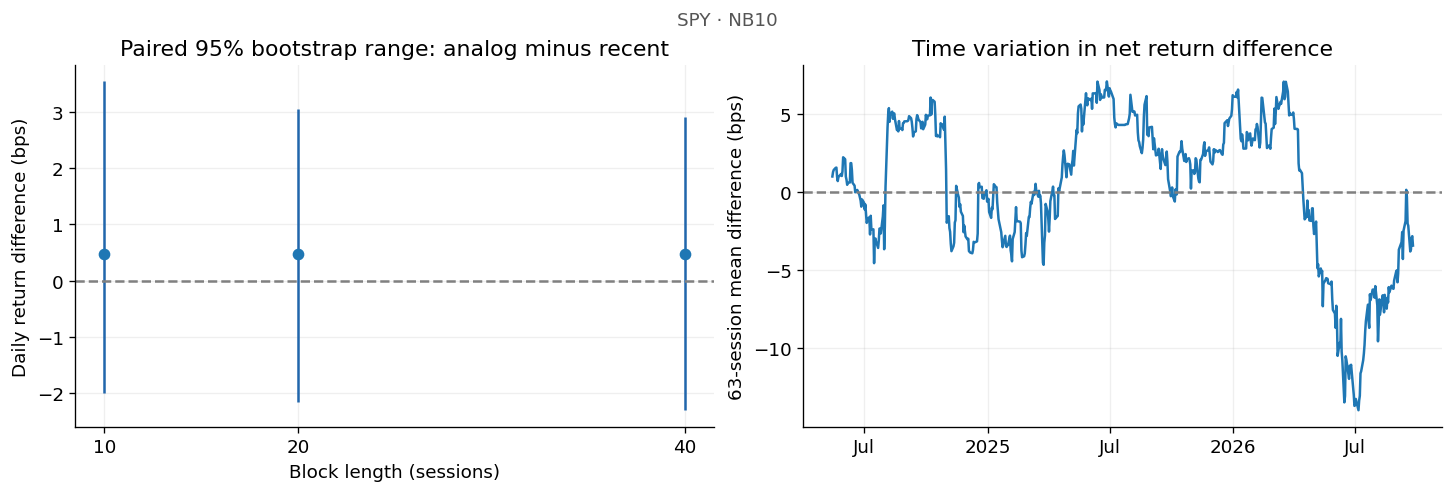

In [12]:
diff=(results['analog'][0]['return']-results['recent'][0]['return']).iloc[1:]
rng=np.random.default_rng(SEED);unc=[]
for block in [10,BLOCK,40]:
    draws=[]
    for _ in range(BOOT_REPS):
        starts=rng.integers(0,len(diff)-block+1,int(np.ceil(len(diff)/block)))
        ix=np.concatenate([np.arange(s,s+block) for s in starts])[:len(diff)]
        draws.append(diff.iloc[ix].mean()*1e4)
    unc.append(dict(block=block,mean_daily_difference_bps=diff.mean()*1e4,
        low_bps=np.quantile(draws,.025),high_bps=np.quantile(draws,.975)))
uncertainty=pd.DataFrame(unc);display(uncertainty.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].vlines(uncertainty.block,uncertainty.low_bps,uncertainty.high_bps,color='#2166ac');axes[0].plot(uncertainty.block,uncertainty.mean_daily_difference_bps,'o')
axes[0].axhline(0,color='gray',ls='--');axes[0].set(xticks=[10,20,40],xlabel='Block length (sessions)',ylabel='Daily return difference (bps)',title='Paired 95% bootstrap range: analog minus recent')
axes[1].plot(diff.index,diff.rolling(63).mean()*1e4);axes[1].axhline(0,color='gray',ls='--')
axes[1].set(ylabel='63-session mean difference (bps)',title='Time variation in net return difference');date_axis(axes[1])
finish(fig,'05_uncertainty.png')

## 6. Ledger tests, reproducibility and research handoff
The checks below reconcile every trade with the analytical account factor, verify zero-cost and cash identities, compare fees under unchanged decisions, and poison unavailable future outcome columns before rebuilding decisions. Outcome columns are used only for source/target validation and ex-post scoring; they are never consulted by the entry rule. Export both schedules (including skipped signals) and actual trades, plus daily ledgers. No intraday risk or capacity claim is supported by this daily dataset.

Before prospective use, freeze the forecast snapshot protocol, chosen rule, evaluation dates and cost assumptions. Then collect a genuinely new interval; review realized forecast quality and execution costs without repeatedly changing the rule. A failure to outperform is a valid research result. Further experiments belong in supplements, preserving the original ten-notebook sequence.

In [14]:
for m,(l,t) in results.items():
    if len(t):
        c=COST_BPS/1e4
        expected=(t.exit_price/t.entry_price)*(1-c)/(1+c)-1
        assert np.allclose(t.net_return,expected,atol=1e-12)
        assert (t.entry_date>t.signal_date).all()
        assert np.allclose(t.entry_fee,t.budget*c/(1+c))
        assert np.isclose(t.entry_fee.sum()+t.exit_fee.sum(),l.fee.sum())
    assert np.isclose(np.prod(1+l['return']),l.equity.iloc[-1]/CAPITAL)
assert results['cash'][0].equity.eq(CAPITAL).all()
for m,g in costs.groupby('strategy'):
    assert (np.diff(g.sort_values('cost_bps').total_return)<=1e-12).all()
# A zero-cost single trade must equal its exact allocation-weighted price move.
one=plan.iloc[[0]].copy();one['weight']=.4
l,t=simulate(one,0)
assert np.isclose(l.equity.iloc[-1]/CAPITAL,1+.4*(t.exit_price.iloc[0]/t.entry_price.iloc[0]-1))
# Explicit decision-input audit: changing realized outcomes cannot change rule outputs.
def decision_weights_only(f):
    ok=f.supported.astype(bool)&(f['mean']>f.threshold)
    return np.minimum.reduce([np.full(len(f),MAX_WEIGHT),VOL_TARGET/f.vol_ann,TAIL_BUDGET/np.maximum(-np.expm1(f.q10),1e-6)])*ok
poison=plan.copy();poison['actual']=1e6
assert np.allclose(decision_weights_only(poison),plan.weight)
assert np.allclose(vol.iloc[:window[0]+1],np.log(price.iloc[:window[0]+1]).diff().rolling(VOL_WINDOW).std()*np.sqrt(252),equal_nan=True)
# Source forecasts retained separately; all output files are isolated from inputs.
for m,(l,t) in results.items():
    l.to_csv(OUT/f'{m}_daily_ledger.csv');t.to_csv(OUT/f'{m}_trades.csv',index=False)
for m,p in plans.items():p.to_csv(OUT/f'{m}_decision_schedule.csv',index=False)
for name,f in [('strategy_metrics',summary),('cost_sensitivity',costs),('horizon_offset_sensitivity',sensitivity),('paired_uncertainty',uncertainty)]:
    f.to_csv(OUT/(name+'.csv'),index=(name=='strategy_metrics'))
parameters=dict(primary_horizon=PRIMARY_H,initial_capital=CAPITAL,cost_bps=COST_BPS,edge_buffer_bps=EDGE_BUFFER_BPS,
 annual_vol_target=VOL_TARGET,tail_budget=TAIL_BUDGET,max_weight=MAX_WEIGHT,vol_window=VOL_WINDOW,
 cost_grid=COST_GRID,bootstrap_replicates=BOOT_REPS,seed=SEED,cash_return=0,shorting=False,leverage=False)
(OUT/'decision_configuration.json').write_text(json.dumps(parameters,indent=2))
manifest=dict(notebook='10 — Trading decision layer',source=source,parameters=parameters,
 input_hashes={name:digest(INPUT_DIR/name) for name in ['forecasts.csv','forecast_configuration.json','run_manifest.json']},
 market_sha256=digest(MARKET_PATH),executed_utc=datetime.now(timezone.utc).isoformat(),
 versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__),
 validation='All code cells executed; target, ledger, cost and decision-input assertions passed',
 scope='Exploratory historical adjusted-price simulation; no prospective or execution-grade performance claim')
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
a=summary.loc['analog'];b=summary.loc['recent'];bh=summary.loc['buy_hold']
display(Markdown(f"**Primary result:** analog total return {a.total_return:.2%}, recent-rule return {b.total_return:.2%}, buy-and-hold {bh.total_return:.2%}; all at {COST_BPS:g} bps per side over the same calendar."))
display(Markdown(f"**Risk and participation:** analog maximum drawdown {a.max_drawdown:.2%}, mean exposure {a.mean_exposure:.1%}, {int(a.trades)} completed trades. Different exposure means raw return differences are not risk-adjusted alpha."))
print('PASS: exact trade accounting, fees, self-financing wealth, cash, cost monotonicity, timing and unavailable-outcome checks.')

**Primary result:** analog total return 4.49%, recent-rule return 0.99%, buy-and-hold 58.52%; all at 5 bps per side over the same calendar.

**Risk and participation:** analog maximum drawdown -9.74%, mean exposure 27.4%, 100 completed trades. Different exposure means raw return differences are not risk-adjusted alpha.

PASS: exact trade accounting, fees, self-financing wealth, cash, cost monotonicity, timing and unavailable-outcome checks.


## References and completion of the core sequence
- [Hyndman & Athanasopoulos: time-series cross-validation](https://otexts.com/fpp3/tscv.html): chronological evaluation with information available at each origin.
- [FINRA: exchange-traded funds and products](https://www.finra.org/investors/investing/investment-products/exchange-traded-funds-and-products): spreads and other trading costs; this notebook's numerical cost scenarios are assumptions, not values supplied by FINRA.
- [FINRA: order types](https://www.finra.org/investors/investing/investment-products/stocks/order-types): execution-price uncertainty and order constraints.

**The original NB1–NB10 sequence is complete.** The progression connects geometry, scales, reconstructed states, recurrence, local flow, early warnings, empirical regimes, bifurcation diagnostics, forecast distributions and now explicit hypothetical decisions. Each stage retains its uncertainty; none establishes a deterministic market attractor or guaranteed trading edge.